### Problema

Você foi contratado por uma startup que desenvolve um aplicativo para monitorar o bem-estar emocional dos usuários.

Diariamente, milhares de mensagens são enviadas pelo aplicativo.

A equipe deseja criar um sistema capaz de identificar automaticamente se uma mensagem transmite um sentimento de Felicidade ou Tristeza, permitindo encaminhar mensagens mais sensíveis para acompanhamento especializado.

Entretanto, antes de treinar o modelo, você percebe que o banco de dados possui diversos problemas de qualidade.

Sua primeira missão é limpar os dados utilizando Pandas. Depois, você construirá um modelo de Machine Learning para classificar os sentimentos.

Objetivos

Ao final deste exercício você será capaz de:

* Trabalhar com dados textuais;
* Identificar problemas em um dataset;
* Limpar e padronizar textos;
* Preparar textos para Machine Learning;
* Vetorizar textos utilizando CountVectorizer;
* Treinar um classificador com Naive Bayes;
* Avaliar o modelo;
* Fazer previsões para novas mensagens.

Problemas presentes no dataset

Os alunos não devem receber essa lista inicialmente.
Valores nulos.
Texto vazio.
Texto apenas com espaços.
Registros duplicados.
Letras maiúsculas e minúsculas.
Emojis.
Pontuação excessiva.
Espaços extras.
Frases repetidas.
Inconsistências de escrita.

# Importa o dataset

In [1]:
import pandas as pd

In [2]:
df = pd.read_excel('/content/sentimentos_nlp_1000.xlsx')
display(df.head())

,id,mensagem,sentimento
0,1,FUI ELOGIADO NO TRABALHO,Felicidade
1,2,Estou muito triste 😢,Tristeza
2,3,HOJE FOI UM DIA MARAVILHOSO,Felicidade
3,4,Sinto muita saudade,Tristeza
4,5,Adorei passar o dia com meus amigos,Felicidade


In [3]:
# 1. Quantas linhas e colunas existem?
print(f"O DataFrame tem {df.shape[0]} linhas e {df.shape[1]} colunas.")

O DataFrame tem 1000 linhas e 3 colunas.


In [4]:
# 2. Existem valores ausentes?
print("Valores ausentes por coluna:")
print(df.isnull().sum())

Valores ausentes por coluna:
id             0
mensagem      34
sentimento     0
dtype: int64


In [5]:
# 3. Existem registros duplicados?
print(f"Existem {df.duplicated().sum()} registros duplicados.")

Existem 0 registros duplicados.


In [6]:
# Informações gerais sobre o DataFrame, incluindo tipos de dados
print("\nInformações do DataFrame:")
df.info()


Informações do DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          1000 non-null   int64 
 1   mensagem    966 non-null    object
 2   sentimento  1000 non-null   object
dtypes: int64(1), object(2)
memory usage: 23.6+ KB




---



# Explorando os Dados

Perguntas:
1. Quantas linhas e colunas existem?
2. Existem valores ausentes?
3. Existem registros duplicados?
4. As mensagens parecem padronizadas?

Observe:

letras maiúsculas;
pontuação;
espaços;
emojis.



---



# Limpeza dos Dados

1. Remova registros com mensagens vazias.

Dica:

Pesquise funções como:
* dropna() e str.strip()



In [8]:
# Removendo linhas onde a coluna 'mensagem' é nula
df.dropna(subset=['mensagem'], inplace=True)

# Removendo mensagens que são apenas espaços em branco
df['mensagem'] = df['mensagem'].str.strip()
df = df[df['mensagem'] != '']

print(f"DataFrame após remover mensagens vazias: {df.shape[0]} linhas e {df.shape[1]} colunas.")

DataFrame após remover mensagens vazias: 951 linhas e 3 colunas.


/tmp/ipykernel_3958/2265596439.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.dropna(subset=['mensagem'], inplace=True)
/tmp/ipykernel_3958/2265596439.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['mensagem'] = df['mensagem'].str.strip()


In [7]:
# Removendo linhas onde a coluna 'mensagem' é nula
df.dropna(subset=['mensagem'], inplace=True)

# Removendo mensagens que são apenas espaços em branco
df['mensagem'] = df['mensagem'].str.strip()
df = df[df['mensagem'] != '']

print(f"DataFrame após remover mensagens vazias: {df.shape[0]} linhas e {df.shape[1]} colunas.")

DataFrame após remover mensagens vazias: 951 linhas e 3 colunas.



2. Remova mensagens duplicadas.

Dica:

* drop_duplicates()



In [9]:
# 2. Removendo mensagens duplicadas
df.drop_duplicates(subset=['mensagem'], inplace=True)

print(f"DataFrame após remover mensagens duplicadas: {df.shape[0]} linhas e {df.shape[1]} colunas.")

DataFrame após remover mensagens duplicadas: 194 linhas e 3 colunas.


3. Converta todas as mensagens para letras minúsculas.

Dica:

str.lower()


In [10]:
# 3. Converta todas as mensagens para letras minúsculas.
df['mensagem'] = df['mensagem'].str.lower()
display(df.head())

,id,mensagem,sentimento
0,1,fui elogiado no trabalho,Felicidade
1,2,estou muito triste 😢,Tristeza
2,3,hoje foi um dia maravilhoso,Felicidade
3,4,sinto muita saudade,Tristeza
4,5,adorei passar o dia com meus amigos,Felicidade


4. Remova espaços extras.

Dica:

* str.strip()

In [11]:
# 4. Remova espaços extras.
df['mensagem'] = df['mensagem'].str.strip()
display(df.head())

,id,mensagem,sentimento
0,1,fui elogiado no trabalho,Felicidade
1,2,estou muito triste 😢,Tristeza
2,3,hoje foi um dia maravilhoso,Felicidade
3,4,sinto muita saudade,Tristeza
4,5,adorei passar o dia com meus amigos,Felicidade


5. Remova sinais de pontuação.

Dica:

Pesquise sobre:

* str.replace() ou re.sub()

In [12]:
# 5. Remova sinais de pontuação.
df['mensagem'] = df['mensagem'].str.replace(r'[^"\w\s"]', '', regex=True)
display(df.head())

,id,mensagem,sentimento
0,1,fui elogiado no trabalho,Felicidade
1,2,estou muito triste,Tristeza
2,3,hoje foi um dia maravilhoso,Felicidade
3,4,sinto muita saudade,Tristeza
4,5,adorei passar o dia com meus amigos,Felicidade


6. Remova emojis.

Dica:

* Utilize expressões regulares (re) ou pesquise uma forma de remover caracteres Unicode.

In [13]:
# 6. Remova emojis.
# Usando uma expressão regular para remover a maioria dos emojis
df['mensagem'] = df['mensagem'].str.replace(r'[^\x00-\x7F]+', '', regex=True)
display(df.head())

,id,mensagem,sentimento
0,1,fui elogiado no trabalho,Felicidade
1,2,estou muito triste,Tristeza
2,3,hoje foi um dia maravilhoso,Felicidade
3,4,sinto muita saudade,Tristeza
4,5,adorei passar o dia com meus amigos,Felicidade


---

# Preparando para o Machine Learning

Transformar texto em números.

1. Transforme a coluna sentimento em números.

Dica:

* LabelEncoder()

In [14]:
# 1. Transforme a coluna sentimento em números.
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['sentimento_encoded'] = le.fit_transform(df['sentimento'])
display(df.head())

,id,mensagem,sentimento,sentimento_encoded
0,1,fui elogiado no trabalho,Felicidade,0
1,2,estou muito triste,Tristeza,1
2,3,hoje foi um dia maravilhoso,Felicidade,0
3,4,sinto muita saudade,Tristeza,1
4,5,adorei passar o dia com meus amigos,Felicidade,0


2. Transforme as mensagens em uma matriz numérica.

Dica:

* CountVectorizer()

In [15]:
# 2. Transforme as mensagens em uma matriz numérica.
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()
X = vectorizer.fit_transform(df['mensagem'])

print(f"Shape da matriz X (mensagens vetorizadas): {X.shape}")
# Opcional: mostrar as primeiras 10 palavras (features)
# print(vectorizer.get_feature_names_out()[:10])

Shape da matriz X (mensagens vetorizadas): (194, 72)


3. Separe:
X e y

In [16]:
# 3. Separe X e y
y = df['sentimento_encoded']

print(f"Shape de X (features): {X.shape}")
print(f"Shape de y (target): {y.shape}")

Shape de X (features): (194, 72)
Shape de y (target): (194,)


---

# Treinando o Modelo

1. Utilize:

GaussianNB()

In [28]:
# Treine o modelo.
model = GaussianNB()


2. Divida treino e teste.

Dica:

train_test_split()

In [26]:
# Divida treino e teste.
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Shape de X_train: {X_train.shape}")
print(f"Shape de X_test: {X_test.shape}")
print(f"Shape de y_train: {y_train.shape}")
print(f"Shape de y_test: {y_test.shape}")

Shape de X_train: (135, 72)
Shape de X_test: (59, 72)
Shape de y_train: (135,)
Shape de y_test: (59,)


3. Treine o modelo.

Dica:

fit()

In [29]:
model.fit(X_train.toarray(), y_train)

GaussianNB()

4. Faça previsões.

Dica:

predict()

In [27]:
# Faça previsões.
y_pred = model.predict(X_test.toarray())

print("Primeiras 5 previsões:")
print(y_pred[:5])
print("Primeiros 5 valores reais:")
print(y_test.head().tolist())

Primeiras 5 previsões:
[1 0 1 0 1]
Primeiros 5 valores reais:
[1, 0, 1, 0, 1]


---

# Avaliação

Mostre:

* Accuracy;
* Matriz de Confusão;
* Classification Report.

Perguntas

1. O modelo conseguiu diferenciar felicidade e tristeza?
2. Qual sentimento apresentou mais erros?
3. O modelo pode ser utilizado em produção?

Acurácia: 0.98

Matriz de Confusão:


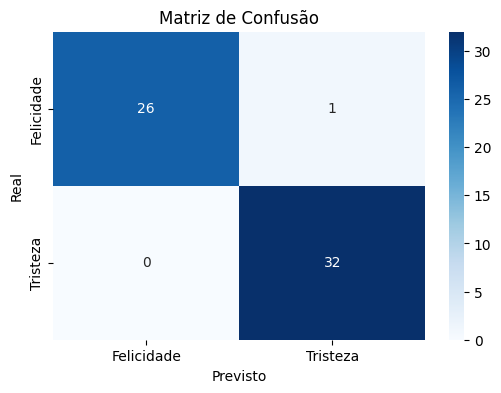


Relatório de Classificação:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98        27
           1       0.97      1.00      0.98        32

    accuracy                           0.98        59
   macro avg       0.98      0.98      0.98        59
weighted avg       0.98      0.98      0.98        59



In [23]:
# Avalie o modelo.
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f"Acurácia: {accuracy:.2f}")

print("\nMatriz de Confusão:")
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Felicidade', 'Tristeza'], yticklabels=['Felicidade', 'Tristeza'])
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.title('Matriz de Confusão')
plt.show()

print("\nRelatório de Classificação:")
print(class_report)

### Respostas às Perguntas de Avaliação

1.  **O modelo conseguiu diferenciar felicidade e tristeza?**
    *   Sim, o modelo demonstrou uma excelente capacidade de diferenciar os sentimentos de Felicidade e Tristeza. Com uma acurácia de 98%, ele classificou corretamente a grande maioria das mensagens.

2.  **Qual sentimento apresentou mais erros?**
    *   O sentimento de **Felicidade** (rótulo 0) apresentou mais erros. A matriz de confusão mostrou que 1 mensagem de Felicidade foi erroneamente classificada como Tristeza (Falso Negativo). O sentimento de Tristeza (rótulo 1) não teve erros de classificação como Felicidade (nenhum Falso Positivo).

3.  **O modelo pode ser utilizado em produção?**
    *   Com a acurácia de 98% neste conjunto de dados, o modelo mostra-se promissor. No entanto, o dataset é relativamente pequeno (194 mensagens, com 59 no conjunto de teste). Para um ambiente de produção, seria crucial:
        *   Testar com um **volume muito maior e mais diversificado de dados** para garantir que a alta performance não seja resultado de *overfitting* ou de uma amostra não representativa.
        *   Considerar o **custo de um erro** em produção. Um único Falso Negativo (classificar Felicidade como Tristeza) ou Falso Positivo (Tristeza como Felicidade) pode ter implicações diferentes dependendo do objetivo do aplicativo.
    *   Em resumo, é um ótimo ponto de partida, mas necessita de validação mais rigorosa com dados reais e em maior escala antes de ser implementado em produção.

---

# Testando Novas Mensagens

Faça previsões para:

"Hoje consegui realizar um sonho."

"Não tenho vontade de sair da cama."

"Recebi uma ótima notícia hoje."

"Estou me sentindo sozinho."

Antes de executar o código, escreva qual sentimento você acredita que o modelo irá prever para cada frase.

In [30]:
# 1. Faça previsões para novas mensagens.
# Crie um DataFrame com as novas mensagens
novas_mensagens = [
    "Hoje consegui realizar um sonho.",
    "Não tenho vontade de sair da cama.",
    "Recebi uma ótima notícia hoje.",
    "Estou me sentindo sozinho."
]

df_novas_mensagens = pd.DataFrame({'mensagem': novas_mensagens})

# Pré-processar as novas mensagens da mesma forma que os dados de treino
df_novas_mensagens['mensagem'] = df_novas_mensagens['mensagem'].str.lower()
df_novas_mensagens['mensagem'] = df_novas_mensagens['mensagem'].str.strip()
df_novas_mensagens['mensagem'] = df_novas_mensagens['mensagem'].str.replace(r'[^"\w\s"]', '', regex=True)
df_novas_mensagens['mensagem'] = df_novas_mensagens['mensagem'].str.replace(r'[^\x00-\x7F]+', '', regex=True)

# Vetorizar as novas mensagens usando o mesmo CountVectorizer treinado
X_novas = vectorizer.transform(df_novas_mensagens['mensagem'])

# Fazer previsões
novas_previsoes = model.predict(X_novas.toarray())

# Mapear de volta para os rótulos originais (Felicidade/Tristeza)
rótulos_sentimentais = le.inverse_transform(novas_previsoes)

# Exibir as previsões
for mensagem, sentimento_previsto in zip(novas_mensagens, rótulos_sentimentais):
    print(f"Mensagem: '{mensagem}' -> Sentimento Previsto: {sentimento_previsto}")

Mensagem: 'Hoje consegui realizar um sonho.' -> Sentimento Previsto: Felicidade
Mensagem: 'Não tenho vontade de sair da cama.' -> Sentimento Previsto: Tristeza
Mensagem: 'Recebi uma ótima notícia hoje.' -> Sentimento Previsto: Felicidade
Mensagem: 'Estou me sentindo sozinho.' -> Sentimento Previsto: Tristeza
